# Taller 2 — Notebook 01: Entendimiento de los datos

**MINE-4101 · Predicción de churn para FinAlpes** · **Integrantes:** Daniel Triviño · Nicolás Bedoya

No hay diccionario de datos: revisamos cuántos datos tiene cada columna, determinamos su tipo a mano (sección 4) y
evaluamos la calidad.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')

RUTA_DATOS = '../churn.csv'
RUTA_FIGS = '../figs'
os.makedirs(RUTA_FIGS, exist_ok=True)


## 1. Carga de los datos

`df` con los tipos que infiere pandas; `df_txt` con todo como texto, tal cual viene en el archivo.

In [2]:
df = pd.read_csv(RUTA_DATOS)
df_txt = pd.read_csv(RUTA_DATOS, dtype=str, keep_default_na=False)

print(f'Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}')
print('Columnas:', list(df.columns))
df.head()


Filas: 10,045  |  Columnas: 11
Columnas: ['credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.00,France,Female,46.00,9,0.00,1,1,1,"81,014.50",1
1,689.00,Germany,Male,67.00,9,"157,094.78",1,1,1,"99,490.01",0
2,477.00,Spain,Female,48.00,2,"129,120.64",1,0,1,"26,475.79",0
3,573.00,Germany,Female,35.00,9,"206,868.78",2,0,1,"102,986.15",0
4,849.00,France,Male,69.00,7,"71,996.09",1,1,1,"139,065.94",0


## 2. Cantidad de datos por columna

In [3]:
conteo = pd.DataFrame({
    'tipo_pandas': df.dtypes.astype(str),
    'no_nulos': df.notna().sum(),
    'nulos': df.isna().sum(),
    'pct_nulos': (df.isna().mean() * 100).round(2),
    'celdas_vacias_txt': (df_txt.apply(lambda s: s.str.strip()) == '').sum(),
    'valores_unicos': df.nunique(),
})
conteo


,tipo_pandas,no_nulos,nulos,pct_nulos,celdas_vacias_txt,valores_unicos
credit_score,float64,9795,250,2.49,250,461
country,object,10045,0,0.00,0,9
gender,object,10045,0,0.00,0,4
age,float64,9745,300,2.99,300,76
tenure,int64,10045,0,0.00,0,14
balance,float64,9845,200,1.99,200,6240
products_number,int64,10045,0,0.00,0,4
credit_card,int64,10045,0,0.00,0,2
active_member,int64,10045,0,0.00,0,2
estimated_salary,float64,9695,350,3.48,350,9649


## 3. Evidencia para determinar el tipo de cada columna

### 3.1 ¿Se leen como números? ¿Son enteros?

In [4]:
def perfil(col):
    raw = df_txt[col].str.strip()
    no_vacios = raw[raw != '']
    num = pd.to_numeric(no_vacios, errors='coerce')
    info = {
        'columna': col,
        'tipo_pandas': str(df[col].dtype),
        'valores_unicos': df[col].nunique(),
        'pct_lectura_numerica': round(num.notna().mean() * 100, 2) if len(no_vacios) else np.nan,
    }
    if num.notna().any():
        info['min'] = num.min()
        info['max'] = num.max()
        info['todos_enteros'] = bool((num.dropna() % 1 == 0).all())
    return info

perfiles = pd.DataFrame([perfil(c) for c in df.columns]).set_index('columna')
perfiles


,tipo_pandas,valores_unicos,pct_lectura_numerica,min,max,todos_enteros
columna,,,,,,
credit_score,float64,461,100.00,95.00,"1,200.00",True
country,object,9,0.00,NaN,NaN,NaN
gender,object,4,0.00,NaN,NaN,NaN
age,float64,76,100.00,-1.00,210.00,True
tenure,int64,14,100.00,-2.00,25.00,True
balance,float64,6240,100.00,0.00,"250,898.09",False
products_number,int64,4,100.00,1.00,4.00,True
credit_card,int64,2,100.00,0.00,1.00,True
active_member,int64,2,100.00,0.00,1.00,True


In [5]:
# Columnas mezcladas: casi todo número, pero con algunos valores que no se pueden leer como número
mezcladas = perfiles[(perfiles['pct_lectura_numerica'] > 0) & (perfiles['pct_lectura_numerica'] < 100)].index
if len(mezcladas) == 0:
    print('No hay columnas mezcladas: cada columna es 100% numérica o 100% texto.')
for col in mezcladas:
    raw = df_txt[col].str.strip()
    raros = raw[(raw != '') & pd.to_numeric(raw, errors='coerce').isna()]
    print(f'{col}: {len(raros)} valores no numéricos ->', raros.value_counts().head(10).to_dict())


No hay columnas mezcladas: cada columna es 100% numérica o 100% texto.


### 3.2 Valores de cada columna

Conteo de cada valor en columnas con 15 valores distintos o menos; resumen numérico en las demás.

In [6]:
for col in df.columns:
    s = df[col]
    print('=' * 72)
    print(f'{col}  |  tipo pandas: {s.dtype}  |  únicos: {s.nunique()}  |  nulos: {s.isna().sum()}')
    if s.nunique() <= 15:
        print(s.value_counts(dropna=False).sort_index().to_string())
    else:
        print(s.describe().to_string())
        print('Algunos valores:', sorted(s.dropna().unique())[:8], '...')


credit_score  |  tipo pandas: float64  |  únicos: 461  |  nulos: 250
count   9,795.00
mean      650.69
std        97.09
min        95.00
25%       584.00
50%       652.00
75%       718.00
max     1,200.00
Algunos valores: [95.0, 120.0, 350.0, 351.0, 358.0, 359.0, 363.0, 365.0] ...
country  |  tipo pandas: object  |  únicos: 9  |  nulos: 0
country
FRANCE        22
France      5003
GERMANY        9
Germany     2502
SPAIN          9
Spain       2475
france        17
germany        6
spain          2
gender  |  tipo pandas: object  |  únicos: 4  |  nulos: 0
gender
F           14
Female    4551
M           16
Male      5464
age  |  tipo pandas: float64  |  únicos: 76  |  nulos: 300
count   9,745.00
mean       38.94
std        10.73
min        -1.00
25%        32.00
50%        37.00
75%        44.00
max       210.00
Algunos valores: [-1.0, 0.0, 5.0, 18.0, 19.0, 20.0, 21.0, 22.0] ...
tenure  |  tipo pandas: int64  |  únicos: 14  |  nulos: 0
tenure
-2        1
 0      415
 1     1037
 2     10

## 4. Tipos determinados a mano

| Columna | Tipo pandas | Tipo determinado | Por qué |
|---|---|---|---|
| `credit_score` | float64 | Numérica discreta | Solo toma valores enteros; pandas la lee como `float` porque tiene faltantes |
| `country` | object | Categórica nominal | Países, sin orden entre ellos |
| `gender` | object | Categórica nominal | Categorías sin orden |
| `age` | float64 | Numérica discreta | Edad en años enteros; pandas la lee como `float` porque tiene faltantes |
| `tenure` | int64 | Numérica discreta | Valores enteros; por el contexto del negocio, son años de antigüedad como cliente |
| `balance` | float64 | Numérica continua | Monto de dinero, con decimales |
| `products_number` | int64 | Numérica discreta | Cuenta cuántos productos tiene el cliente |
| `credit_card` | int64 | Binaria | Solo 0/1: tiene o no tarjeta de crédito |
| `active_member` | int64 | Binaria | Solo 0/1: es o no cliente activo |
| `estimated_salary` | float64 | Numérica continua | Monto de dinero, con decimales |
| `churn` | int64 | Binaria | Solo 0/1: abandonó o no (es la variable objetivo) |

## 5. Calidad de los datos

Completitud, unicidad, validez y consistencia, con las funciones de `calidad.py`. El `ESQUEMA` traduce a código la
tabla de tipos de la sección 4.

In [7]:
import calidad as cal

ESQUEMA = {
    'credit_score': 'discreta',
    'country': 'categorica',
    'gender': 'categorica',
    'age': 'discreta',
    'tenure': 'discreta',
    'balance': 'continua',
    'products_number': 'discreta',
    'credit_card': 'binaria',
    'active_member': 'binaria',
    'estimated_salary': 'continua',
    'churn': 'binaria',
}
assert set(ESQUEMA) == set(df.columns), 'El esquema debe cubrir exactamente las columnas del dataset'

# Abreviaturas que consideramos el mismo valor (las usan los chequeos de dominio y de formato)
EQUIVALENCIAS = {'gender': {'M': 'Male', 'F': 'Female'}}


### 5.1 Completitud

In [8]:
comp = cal.completitud(df)
comp


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,completitud,credit_score,valores faltantes,250,2.49,
1,completitud,country,valores faltantes,0,0.00,
2,completitud,gender,valores faltantes,0,0.00,
3,completitud,age,valores faltantes,300,2.99,
4,completitud,tenure,valores faltantes,0,0.00,
5,completitud,balance,valores faltantes,200,1.99,
6,completitud,products_number,valores faltantes,0,0.00,
7,completitud,credit_card,valores faltantes,0,0.00,
8,completitud,active_member,valores faltantes,0,0.00,
9,completitud,estimated_salary,valores faltantes,350,3.48,


In [9]:
comp_filas, faltantes_por_fila = cal.completitud_filas(df)
display(comp_filas)
faltantes_por_fila


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,completitud,(fila),filas con al menos un faltante,1100,10.95,


,n_filas
faltantes_en_la_fila,
0,8945
1,1100


### 5.2 Unicidad

Sin identificador de cliente: buscamos filas completas repetidas, exactas y con el texto normalizado.

In [10]:
unic_exacta, dup_exactos = cal.unicidad(df)
unic_norm, dup_norm = cal.unicidad(df, normalizar_texto=True)
display(cal.juntar(unic_exacta, unic_norm))
print('Algunas filas duplicadas (exactas), con su original:')
dup_exactos.sort_values(list(df.columns)).head(10)


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,unicidad,todas las columnas,filas duplicadas (exactas),45,0.45,
1,unicidad,todas las columnas,filas duplicadas (texto normalizado),45,0.45,


Algunas filas duplicadas (exactas), con su original:


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5428,497.00,France,Female,29.00,4,"85,646.81",1,0,0,"63,233.02",1
5672,497.00,France,Female,29.00,4,"85,646.81",1,0,0,"63,233.02",1
2390,499.00,Germany,Male,36.00,5,"131,142.53",2,1,0,"174,918.46",0
7450,499.00,Germany,Male,36.00,5,"131,142.53",2,1,0,"174,918.46",0
2784,528.00,France,Female,27.00,7,"176,227.07",2,0,1,"139,481.53",0
6920,528.00,France,Female,27.00,7,"176,227.07",2,0,1,"139,481.53",0
975,538.00,France,Female,38.00,8,"88,758.95",2,0,0,"28,226.15",1
6632,538.00,France,Female,38.00,8,"88,758.95",2,0,0,"28,226.15",1
6854,539.00,France,Male,30.00,0,0.00,2,1,0,"160,979.66",0
8174,539.00,France,Male,30.00,0,0.00,2,1,0,"160,979.66",0


### 5.3 Validez

**Según el tipo determinado.**

In [11]:
val_tipos = cal.validez_tipos(df, ESQUEMA)
val_tipos


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,validez,credit_score,no numéricos (esperado discreta),0,0.00,
1,validez,credit_score,no enteros (esperado discreta),0,0.00,
2,validez,country,valores numéricos en una categoría,0,0.00,
3,validez,gender,valores numéricos en una categoría,0,0.00,
4,validez,age,no numéricos (esperado discreta),0,0.00,
5,validez,age,no enteros (esperado discreta),0,0.00,
6,validez,tenure,no numéricos (esperado discreta),0,0.00,
7,validez,tenure,no enteros (esperado discreta),0,0.00,
8,validez,balance,no numéricos (esperado continua),0,0.00,
9,validez,products_number,no numéricos (esperado discreta),0,0.00,


**Rangos válidos (reglas de negocio):**

- `credit_score`: 150–950, la escala de DataCrédito Experian
  ([Valora Analitik](https://www.valoraanalitik.com/puntaje-de-credito-que-es-y-como-funciona-en-colombia/),
  [La FM](https://www.lafm.com.co/economia/cual-es-el-mejor-puntaje-de-datacredito)).
- `age`: 18–100. Mayoría de edad a los 18
  ([Ley 27 de 1977](https://www.dmsjuridica.com/buscador_20179478954/legislacion/leyes/2024/02/06/ley-27-de-1977/?pdf=3973));
  hay productos con codeudor desde los 14
  ([Vanguardia](https://www.vanguardia.com/economia/2025/07/21/desde-los-14-anos-asi-puede-tener-tarjeta-de-credito-en-colombia-en-2025/)),
  pero son la excepción.
- `tenure` y `estimated_salary`: mayores o iguales a 0.
- `balance`: sin rango, porque un saldo puede ser negativo (por ejemplo, un sobregiro).

In [12]:
# Rangos válidos por columna: (mínimo, máximo); None = sin límite.
RANGOS = {
    'credit_score': (150, 950),   # escala de DataCrédito Experian
    'age': (18, 100),             # mayoría de edad y tope de plausibilidad
    'tenure': (0, None),          # la antigüedad no puede ser negativa
    'estimated_salary': (0, None),  # un salario no puede ser negativo
}                                 # balance no lleva rango: un saldo puede ser negativo (sobregiro)

val_rangos, filas_fuera_rango = cal.validez_rangos(df, RANGOS, devolver_filas=True)
display(val_rangos)

with pd.option_context('display.max_rows', None):
    for col, filas in filas_fuera_rango.items():
        print('=' * 90)
        print(f'{col}: {len(filas)} filas fuera del rango {RANGOS[col]}')
        if len(filas):
            display(filas.sort_values(col))


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,validez,credit_score,"fuera del rango [150, 950]",4,0.04,"95.0, 120.0, 999.0, 1200.0"
1,validez,age,"fuera del rango [18, 100]",6,0.06,"-1.0, 0.0, 5.0, 130.0, 150.0, 210.0"
2,validez,tenure,"fuera del rango [0, None]",1,0.01,-2
3,validez,estimated_salary,"fuera del rango [0, None]",3,0.03,"-5000.0, -120.5, -1.0"


credit_score: 4 filas fuera del rango (150, 950)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
6424,95.00,France,Female,39.00,3,"118,336.14",1,1,0,"184,691.77",0
1881,120.00,Germany,Female,38.00,8,"103,653.51",2,1,1,"137,079.86",0
9043,999.00,Spain,Male,37.00,2,0.00,2,0,1,"187,816.59",0
1795,"1,200.00",Spain,Female,39.00,9,0.00,2,1,0,"28,368.37",0


age: 6 filas fuera del rango (18, 100)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
7227,674.00,France,Male,-1.00,7,"144,889.18",1,1,1,"102,591.90",1
1819,516.00,France,Female,0.00,9,0.00,2,0,1,"33,266.29",0
1776,702.00,France,Female,5.00,6,"149,218.39",1,1,1,"9,633.01",0
992,850.00,France,Male,130.00,5,0.00,2,1,1,"44,827.47",0
4534,635.00,Spain,Male,150.00,2,0.00,2,0,0,"117,173.80",0
4031,433.00,France,Female,210.00,10,0.00,1,1,1,"87,711.61",0


tenure: 1 filas fuera del rango (0, None)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
6306,798.00,France,Male,36.00,-2,0.00,2,1,1,"159,044.10",0


estimated_salary: 3 filas fuera del rango (0, None)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
1984,587.00,Germany,Male,46.00,9,"107,850.82",1,1,0,"-5,000.00",1
2348,773.00,France,Female,50.00,4,0.00,2,1,0,-120.50,0
4679,811.00,Germany,Female,28.00,4,"167,738.82",2,1,1,-1.00,0


**Valores permitidos:** `country` ∈ {France, Germany, Spain}; `gender` ∈ {Female, Male}. Aparte se muestran los valores
sin equivalente en el dominio (los que no son solo otra forma de escribir un valor válido).

In [13]:
DOMINIOS = {
    'country': ['France', 'Germany', 'Spain'],
    'gender': ['Female', 'Male'],
}

val_dominio, filas_sin_equivalente = cal.validez_dominio(df, DOMINIOS, EQUIVALENCIAS, devolver_filas=True)
display(val_dominio)

for col, filas in filas_sin_equivalente.items():
    print('=' * 90)
    print(f'{col}: {len(filas)} filas con valores que no corresponden a ningún valor permitido')
    if len(filas):
        display(filas[col].value_counts())
        display(filas)


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,validez,country,fuera de los valores permitidos,65,0.65,"GERMANY, FRANCE, SPAIN, spain , france , germany"
1,validez,country,sin equivalente en el dominio,0,0.00,
2,validez,gender,fuera de los valores permitidos,30,0.30,"F, M"
3,validez,gender,sin equivalente en el dominio,0,0.00,


country: 0 filas con valores que no corresponden a ningún valor permitido
gender: 0 filas con valores que no corresponden a ningún valor permitido


**Atípicos (IQR):** fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Atípico no implica error, y un valor imposible puede
quedar dentro de los límites si la columna es muy dispersa.

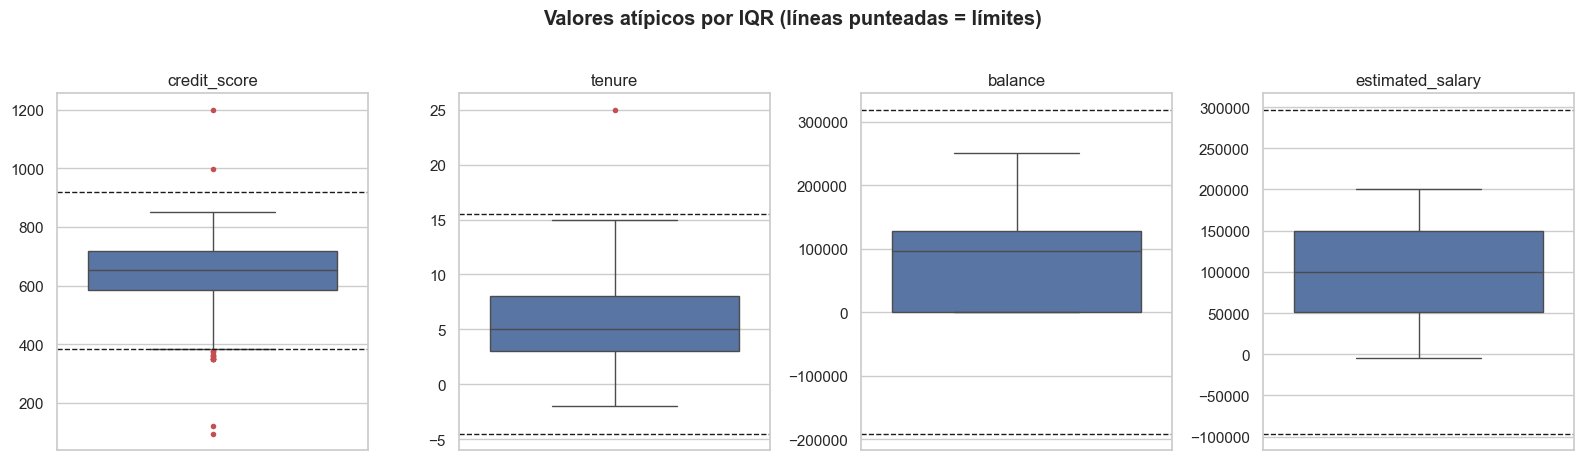

,q1,q3,iqr,limite_inferior,limite_superior
credit_score,584.00,718.00,134.00,383.00,919.00
tenure,3.00,8.00,5.00,-4.50,15.50
balance,0.00,"127,559.97","127,559.97","-191,339.96","318,899.93"
estimated_salary,"51,013.65","149,382.88","98,369.22","-96,540.18","296,936.71"


In [14]:
COLS_ATIPICOS = ['credit_score', 'tenure', 'balance', 'estimated_salary']

resultados_iqr = {col: cal.atipicos_iqr(df, col) for col in COLS_ATIPICOS}

fig, axes = plt.subplots(1, len(COLS_ATIPICOS), figsize=(16, 4.5))
for ax, col in zip(axes, COLS_ATIPICOS):
    lim = resultados_iqr[col][1]
    sns.boxplot(y=df[col], ax=ax, color='#4C72B0',
                flierprops=dict(marker='o', markersize=4, markerfacecolor='#C44E52', markeredgecolor='none'))
    ax.axhline(lim['limite_inferior'], color='k', ls='--', lw=1)
    ax.axhline(lim['limite_superior'], color='k', ls='--', lw=1)
    ax.set_title(col); ax.set_ylabel('')
fig.suptitle('Valores atípicos por IQR (líneas punteadas = límites)', fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/01_atipicos_boxplot.png', bbox_inches='tight'); plt.show()

limites_iqr = pd.DataFrame({col: r[1] for col, r in resultados_iqr.items()}).T
limites_iqr


In [15]:
val_atipicos = cal.juntar(*[r[0] for r in resultados_iqr.values()])
val_atipicos


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,validez,credit_score,atípicos por debajo de 383.00 (IQR),14,0.14,"95.0, 120.0, 350.0 ... 365.0, 373.0, 376.0"
1,validez,credit_score,atípicos por encima de 919.00 (IQR),2,0.02,"999.0, 1200.0"
2,validez,tenure,atípicos por debajo de -4.50 (IQR),0,0.00,
3,validez,tenure,atípicos por encima de 15.50 (IQR),1,0.01,25
4,validez,balance,"atípicos por debajo de -191,339.96 (IQR)",0,0.00,
5,validez,balance,"atípicos por encima de 318,899.93 (IQR)",0,0.00,
6,validez,estimated_salary,"atípicos por debajo de -96,540.18 (IQR)",0,0.00,
7,validez,estimated_salary,"atípicos por encima de 296,936.71 (IQR)",0,0.00,


Filas completas de los atípicos:

In [16]:
with pd.option_context('display.max_rows', None):
    for col, (_, lim, abajo, arriba) in resultados_iqr.items():
        print('=' * 90)
        print(f"{col}: límites IQR [{lim['limite_inferior']:,.2f}, {lim['limite_superior']:,.2f}]")
        for lado, filas in [('Por debajo', abajo), ('Por encima', arriba)]:
            print(f'{lado} del límite: {len(filas)} filas')
            if len(filas):
                display(filas)


credit_score: límites IQR [383.00, 919.00]
Por debajo del límite: 14 filas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
341,350.00,France,Female,NaN,3,0.00,1,0,0,"113,796.15",1
563,358.00,Spain,Female,52.00,8,"143,542.36",3,1,0,"141,959.11",1
1055,376.00,Germany,Female,29.00,4,"115,046.74",4,1,0,"119,346.88",1
1697,373.00,France,Male,42.00,7,0.00,1,1,0,"77,786.37",1
1881,120.00,Germany,Female,38.00,8,"103,653.51",2,1,1,"137,079.86",0
3431,350.00,France,Female,40.00,0,"111,098.85",1,1,1,"172,321.21",1
5164,376.00,France,Female,46.00,6,0.00,1,1,0,"157,333.69",1
5372,351.00,Germany,Female,57.00,4,"163,146.46",1,1,0,"169,621.69",1
6424,95.00,France,Female,39.00,3,"118,336.14",1,1,0,"184,691.77",0
6997,359.00,France,Female,44.00,6,"128,747.69",1,1,0,"146,955.71",1


Por encima del límite: 2 filas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
1795,"1,200.00",Spain,Female,39.00,9,0.00,2,1,0,"28,368.37",0
9043,999.00,Spain,Male,37.00,2,0.00,2,0,1,"187,816.59",0


tenure: límites IQR [-4.50, 15.50]
Por debajo del límite: 0 filas
Por encima del límite: 1 filas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5775,589.00,Germany,Female,20.00,25,"121,093.29",2,1,0,"3,529.72",0


balance: límites IQR [-191,339.96, 318,899.93]
Por debajo del límite: 0 filas
Por encima del límite: 0 filas
estimated_salary: límites IQR [-96,540.18, 296,936.71]
Por debajo del límite: 0 filas
Por encima del límite: 0 filas


**Valores negativos** en `tenure`, `age`, `balance` y `estimated_salary` (en `balance`, solo como referencia).

In [17]:
COLS_NO_NEGATIVAS = ['tenure', 'age', 'balance', 'estimated_salary']

val_negativos, filas_negativas = cal.valores_negativos(df, COLS_NO_NEGATIVAS)
display(val_negativos)

for col, filas in filas_negativas.items():
    print('=' * 90)
    print(f'{col}: {len(filas)} filas con valor negativo')
    if len(filas):
        display(filas)


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,validez,tenure,valores negativos,1,0.01,-2
1,validez,age,valores negativos,1,0.01,-1.0
2,validez,balance,valores negativos,0,0.00,
3,validez,estimated_salary,valores negativos,3,0.03,"-5000.0, -120.5, -1.0"


tenure: 1 filas con valor negativo


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
6306,798.00,France,Male,36.00,-2,0.00,2,1,1,"159,044.10",0


age: 1 filas con valor negativo


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
7227,674.00,France,Male,-1.00,7,"144,889.18",1,1,1,"102,591.90",1


balance: 0 filas con valor negativo
estimated_salary: 3 filas con valor negativo


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
1984,587.00,Germany,Male,46.00,9,"107,850.82",1,1,0,"-5,000.00",1
2348,773.00,France,Female,50.00,4,0.00,2,1,0,-120.50,0
4679,811.00,Germany,Female,28.00,4,"167,738.82",2,1,1,-1.00,0


### 5.4 Consistencia

**Formato**, con `M` = `Male` y `F` = `Female`. **Decisión para el `02`:** cada variante pasa a la más común de su grupo.

In [18]:
cons_formato, variantes = cal.consistencia_formato(df, equivalencias=EQUIVALENCIAS)
display(cons_formato)
variantes


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,consistencia,country,mismo valor escrito de varias formas,65,0.65,France/FRANCE/france ; Germany/GERMANY/germany...
1,consistencia,gender,mismo valor escrito de varias formas,30,0.30,Female/F; Male/M


,columna,grupo,variante,n,es_la_mas_comun
0,country,france,France,5003,True
1,country,france,FRANCE,22,False
2,country,france,france,17,False
3,country,germany,Germany,2502,True
4,country,germany,GERMANY,9,False
5,country,germany,germany,6,False
6,country,spain,Spain,2475,True
7,country,spain,SPAIN,9,False
8,country,spain,spain,2,False
9,gender,female,Female,4551,True


**Regla entre columnas:** `age > tenure` (se marcan las filas con `tenure > age`).

In [19]:
# Reglas cruzadas: {nombre: funcion(df) -> True en las filas que INCUMPLEN la regla}
REGLAS_CRUZADAS = {
    'antigüedad mayor que la edad (tenure > age)': lambda d: d['tenure'] > d['age'],
}

cons_reglas = cal.consistencia_reglas(df, REGLAS_CRUZADAS)
display(cons_reglas)

for nombre, regla in REGLAS_CRUZADAS.items():
    incumplen = df[regla(df).fillna(False).astype(bool)]
    print(f'{nombre}: {len(incumplen)} filas')
    display(incumplen)


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,consistencia,varias,antigüedad mayor que la edad (tenure > age),4,0.04,"1776, 1819, 5775, 7227"


antigüedad mayor que la edad (tenure > age): 4 filas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
1776,702.00,France,Female,5.00,6,"149,218.39",1,1,1,"9,633.01",0
1819,516.00,France,Female,0.00,9,0.00,2,0,1,"33,266.29",0
5775,589.00,Germany,Female,20.00,25,"121,093.29",2,1,0,"3,529.72",0
7227,674.00,France,Male,-1.00,7,"144,889.18",1,1,1,"102,591.90",1


### 5.5 Catálogo de hallazgos

In [20]:
catalogo = cal.catalogo(comp, comp_filas, unic_exacta, unic_norm, val_tipos, val_rangos, val_dominio,
                        val_atipicos, val_negativos, cons_formato, cons_reglas)
catalogo


,dimension,columna,chequeo,n_afectados,pct_afectados,ejemplos
0,completitud,(fila),filas con al menos un faltante,1100,10.95,
1,completitud,estimated_salary,valores faltantes,350,3.48,
2,completitud,age,valores faltantes,300,2.99,
3,completitud,credit_score,valores faltantes,250,2.49,
4,completitud,balance,valores faltantes,200,1.99,
5,unicidad,todas las columnas,filas duplicadas (exactas),45,0.45,
6,unicidad,todas las columnas,filas duplicadas (texto normalizado),45,0.45,
7,validez,country,fuera de los valores permitidos,65,0.65,"GERMANY, FRANCE, SPAIN, spain , france , germany"
8,validez,gender,fuera de los valores permitidos,30,0.30,"F, M"
9,validez,credit_score,atípicos por debajo de 383.00 (IQR),14,0.14,"95.0, 120.0, 350.0 ... 365.0, 373.0, 376.0"


## 6. Balance de la variable objetivo (`churn`)

Sobre los datos crudos.

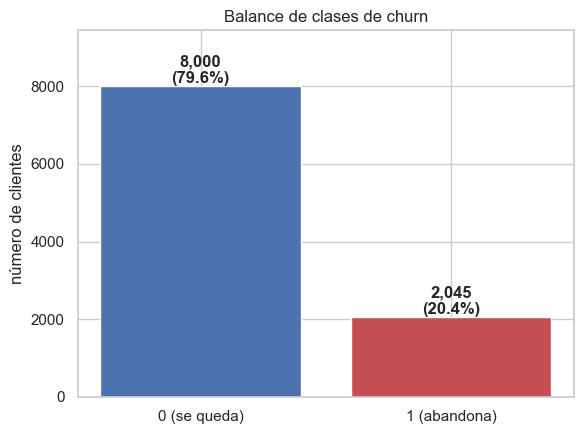

,clientes,pct
churn,,
0,8000,79.60
1,2045,20.40


In [21]:
conteo_churn = df['churn'].value_counts().sort_index()
pct_churn = (conteo_churn / conteo_churn.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(['0 (se queda)', '1 (abandona)'], conteo_churn.values, color=['#4C72B0', '#C44E52'])
for barra, n, p in zip(barras, conteo_churn.values, pct_churn.values):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), f'{n:,}\n({p}%)',
            ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, conteo_churn.max() * 1.18)
ax.set_title('Balance de clases de churn'); ax.set_ylabel('número de clientes')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/01_balance_churn.png', bbox_inches='tight'); plt.show()

pd.DataFrame({'clientes': conteo_churn, 'pct': pct_churn})
